# Customer Churn Prediction with an Artificial Neural Network

This notebook prepares customer data and trains a binary classification model to predict whether a bank customer will leave (`Exited = 1`).

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd

## 2. Load and inspect the dataset

Load the churn data, preview the first rows, and inspect its structure and basic category distributions.

In [2]:
df = pd.read_csv('Churn_Modelling.csv')

In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 3. Initial data inspection

The identifier columns (`RowNumber`, `CustomerId`, and `Surname`) do not describe customer behavior, so they will not be used as model features. The checks below also inspect data types, duplicates, the target balance, and categorical values.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [7]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [8]:
df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

## 4. Clean the feature columns

Remove the identifier fields before modeling, then preview the remaining customer features.

In [9]:
df.drop(columns=['RowNumber', 'CustomerId', 'Surname'],inplace= True)

In [10]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 5. Encode categorical features

Convert `Geography` and `Gender` into numeric dummy variables. `drop_first=True` avoids redundant columns, which leaves 11 input features for the neural network.

In [11]:
df = pd.get_dummies(
    df,
    columns=['Geography', 'Gender'],
    drop_first=True,
    dtype=int
)
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


## 6. Prepare the training and test sets

Separate the predictors (`X`) from the target (`y`), then split the data so the model can be evaluated on unseen customers.

In [12]:
X = df.drop(columns=['Exited'])
y = df['Exited']
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=1, stratify=y_train
)

In [13]:
X

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,0,0,1
9996,516,35,10,57369.61,1,1,1,101699.77,0,0,1
9997,709,36,7,0.00,1,0,1,42085.58,0,0,0
9998,772,42,3,75075.31,2,1,0,92888.52,1,0,1


In [14]:
y

0       1
1       0
2       1
3       0
4       0
       ..
9995    0
9996    0
9997    1
9998    1
9999    0
Name: Exited, Length: 10000, dtype: int64

In [15]:
X_train

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
5292,745,28,6,0.00,2,1,0,154389.18,0,0,0
3879,778,33,9,151772.63,2,0,0,180249.94,0,0,0
6118,632,49,5,167962.70,1,0,0,140201.21,0,0,0
4044,658,32,8,0.00,1,1,1,80410.68,0,0,1
3202,564,33,4,135946.26,1,1,0,63170.00,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
2644,736,27,5,51522.75,1,0,1,192131.77,0,0,1
7970,850,30,6,86449.39,1,1,1,188809.23,0,0,1
2746,620,36,8,0.00,2,1,1,145937.99,0,0,1
8369,684,37,1,126817.13,2,1,1,29995.83,1,0,1


In [16]:
X_test

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
4466,413,35,2,0.00,2,1,1,60972.84,0,1,1
3754,535,35,8,118989.92,1,1,1,135536.72,0,1,1
9601,659,33,7,89939.62,1,1,0,136540.09,0,0,0
9758,556,43,4,125890.72,1,1,1,74854.97,1,0,0
8577,754,65,1,136186.44,1,1,1,121529.59,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...
7788,551,76,2,128410.71,2,1,1,181718.73,0,1,1
1650,625,34,6,0.00,2,0,0,197283.20,0,0,1
1276,635,37,5,113488.68,1,1,0,95611.74,1,0,1
1043,579,35,1,0.00,2,1,0,4460.20,0,0,1


In [17]:
X_train.shape

(6400, 11)

In [18]:
X_test.shape

(2000, 11)

In [19]:
y_train.shape

(6400,)

In [20]:
y_test.shape

(2000,)

## 7. Scale the numeric features

Standardize the input features so they are on comparable scales. This helps the neural network optimize more reliably.

In [21]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [22]:
X_train

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
5292,745,28,6,0.00,2,1,0,154389.18,0,0,0
3879,778,33,9,151772.63,2,0,0,180249.94,0,0,0
6118,632,49,5,167962.70,1,0,0,140201.21,0,0,0
4044,658,32,8,0.00,1,1,1,80410.68,0,0,1
3202,564,33,4,135946.26,1,1,0,63170.00,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
2644,736,27,5,51522.75,1,0,1,192131.77,0,0,1
7970,850,30,6,86449.39,1,1,1,188809.23,0,0,1
2746,620,36,8,0.00,2,1,1,145937.99,0,0,1
8369,684,37,1,126817.13,2,1,1,29995.83,1,0,1


In [23]:
X_train_scaled

array([[ 0.97615457, -1.04738064,  0.34704597, ..., -0.57927478,
        -0.57999647, -1.08586109],
       [ 1.31694942, -0.57204799,  1.37723807, ..., -0.57927478,
        -0.57999647, -1.08586109],
       [-0.19080962,  0.94901649,  0.0036486 , ..., -0.57927478,
        -0.57999647, -1.08586109],
       ...,
       [-0.31473502, -0.2868484 ,  1.0338407 , ..., -0.57927478,
        -0.57999647,  0.92092811],
       [ 0.34620045, -0.19178187, -1.36994088, ...,  1.72629647,
        -0.57999647,  0.92092811],
       [-1.20286705, -1.52271329,  0.0036486 , ..., -0.57927478,
        -0.57999647, -1.08586109]], shape=(6400, 11))

## 8. Build the artificial neural network

Create a small feed-forward network with one hidden layer and a sigmoid output for binary churn prediction.

In [24]:
import tensorflow
from tensorflow import keras 
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input 

In [25]:
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(11, activation="relu"),
    Dense(11, activation="relu"),
    Dense(1, activation="sigmoid")
])

In [26]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 276 (1.08 KB)

 Trainable params: 276 (1.08 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
model.compile(loss = "binary_crossentropy"  , optimizer = "Adam" , metrics= ['accuracy'])

## 9. Train the model

Fit the network on the scaled training data for 100 epochs.

In [28]:
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced", classes=classes, y=y_train
)
class_weights = dict(zip(classes, weights))
USE_CLASS_WEIGHTS = False

early_stop = EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=200,
    validation_data=(X_val_scaled, y_val),
    callbacks=[early_stop],
    class_weight=class_weights if USE_CLASS_WEIGHTS else None
)

Epoch 1/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4989 - loss: 0.7469 - val_accuracy: 0.7987 - val_loss: 0.4889
Epoch 2/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7949 - loss: 0.4696 - val_accuracy: 0.8100 - val_loss: 0.4398
Epoch 3/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8234 - loss: 0.4259 - val_accuracy: 0.8169 - val_loss: 0.4161
Epoch 4/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8345 - loss: 0.4036 - val_accuracy: 0.8331 - val_loss: 0.3978
Epoch 5/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8470 - loss: 0.3832 - val_accuracy: 0.8356 - val_loss: 0.3836
Epoch 6/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8478 - loss: 0.3684 - val_accuracy: 0.8394 - val_loss: 0.3730
Epoch 7/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8455 - loss: 0.3640 - val_accuracy: 0.8381 - val_loss: 0.3702
Epoch 8/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8432 - loss: 0.3812 - val_accu

In [29]:
model.layers[1].get_weights()

[array([[-1.05032779e-01, -8.73271227e-02, -6.67940453e-02,
         -1.13234624e-01,  6.45970941e-01, -1.67938054e-01,
          4.50226128e-01, -8.65469337e-01,  6.34488642e-01,
         -5.10796487e-01, -2.47860029e-01],
        [-7.48769790e-02, -1.53669864e-01, -9.96013521e-04,
          5.54955080e-02,  2.51507580e-01,  2.75060833e-01,
          1.32286832e-01,  8.19209069e-02,  5.91579258e-01,
          2.48517375e-02, -4.65547949e-01],
        [-5.16826272e-01, -6.24811888e-01,  7.65600324e-01,
         -3.42445403e-01, -1.60971239e-01,  3.17710042e-01,
         -1.07825720e+00,  2.24375665e-01, -4.91050452e-01,
         -7.20929623e-01, -1.70134574e-01],
        [ 4.32252645e-01, -5.76678038e-01, -7.76045561e-01,
          1.38992548e-01,  1.19132571e-01, -6.32610321e-01,
          6.10378921e-01, -3.31980407e-01, -4.11366820e-01,
         -4.14921403e-01,  1.38506725e-01],
        [-1.10453084e-01, -2.17415661e-01,  3.51601869e-01,
          3.10468584e-01,  2.63994753e-01, -

## 10. Predict and evaluate

Generate probabilities for the test set, convert them to class labels using a 0.5 threshold, and calculate the final accuracy.

In [30]:
y_log = model.predict(X_test_scaled)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 839us/step


In [31]:
y_pred = (y_log.ravel() >= 0.5).astype(int)

In [32]:
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_log.ravel()))
print("\nClassification report:\n", classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.8605
ROC-AUC: 0.8476118645610171

Classification report:
               precision    recall  f1-score   support

           0       0.88      0.96      0.92      1593
           1       0.75      0.48      0.58       407

    accuracy                           0.86      2000
   macro avg       0.81      0.72      0.75      2000
weighted avg       0.85      0.86      0.85      2000

Confusion matrix:
 [[1527   66]
 [ 213  194]]


## 11. Plot the training 



In [33]:
history.history

{'accuracy': [0.6665624976158142,
  0.8037499785423279,
  0.8237500190734863,
  0.8331249952316284,
  0.8434374928474426,
  0.8459374904632568,
  0.850781261920929,
  0.8551562428474426,
  0.8571875095367432,
  0.8581249713897705,
  0.8557812571525574,
  0.8582812547683716,
  0.8600000143051147,
  0.8579687476158142,
  0.8595312237739563,
  0.8604687452316284,
  0.8629687428474426,
  0.8621875047683716,
  0.8615624904632568,
  0.8617187738418579,
  0.8634374737739563,
  0.8645312786102295,
  0.8656250238418579,
  0.8639062643051147,
  0.8642187714576721,
  0.8635937571525574,
  0.8650000095367432,
  0.864062488079071,
  0.8648437261581421,
  0.8662499785423279,
  0.8646875023841858,
  0.8665624856948853,
  0.8656250238418579,
  0.8650000095367432,
  0.8665624856948853,
  0.8673437237739563,
  0.8657812476158142,
  0.8657812476158142,
  0.8662499785423279,
  0.8653125166893005,
  0.8671875,
  0.8662499785423279,
  0.867968738079071,
  0.8675000071525574,
  0.8657812476158142],
 'loss': 

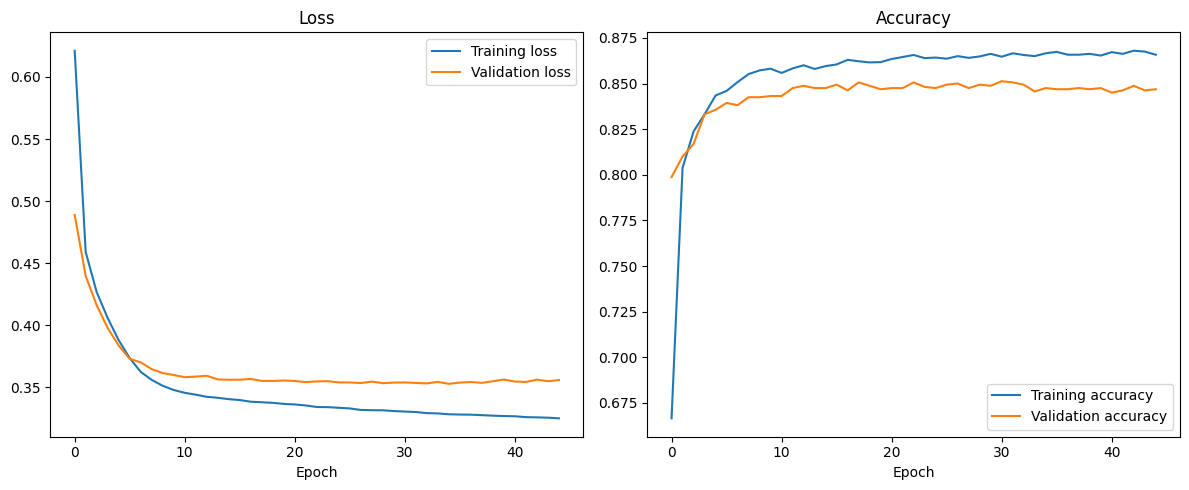

In [34]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(history.history['loss'], label='Training loss')
axes[0].plot(history.history['val_loss'], label='Validation loss')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='Training accuracy')
axes[1].plot(history.history['val_accuracy'], label='Validation accuracy')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.show()

## 12. Compare models and prepare inference

In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

def evaluate_model(name, y_true, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)
    return {
        'model': name,
        'accuracy': accuracy_score(y_true, predictions),
        'precision': precision_score(y_true, predictions, zero_division=0),
        'recall': recall_score(y_true, predictions, zero_division=0),
        'f1': f1_score(y_true, predictions, zero_division=0),
        'roc_auc': roc_auc_score(y_true, probabilities)
    }

ann_probabilities = model.predict(X_test_scaled, verbose=0).ravel()

logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_scaled, y_train)
logistic_probabilities = logistic_model.predict_proba(X_test_scaled)[:, 1]

results = [
    evaluate_model('ANN', y_test, ann_probabilities),
    evaluate_model('Logistic Regression', y_test, logistic_probabilities)
]

try:
    from xgboost import XGBClassifier
    xgb_model = XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        eval_metric='logloss', random_state=1, n_jobs=-1
    )
    xgb_model.fit(X_train, y_train)
    xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]
    results.append(evaluate_model('XGBoost', y_test, xgb_probabilities))
except ImportError:
    print('XGBoost is not installed. Run: %pip install xgboost')

comparison = pd.DataFrame(results).set_index('model')
comparison.sort_values('roc_auc', ascending=False)

XGBoost is not installed. Run: %pip install xgboost


,accuracy,precision,recall,f1,roc_auc
model,,,,,
ANN,0.8605,0.746154,0.476658,0.581709,0.847612
Logistic Regression,0.8115,0.611940,0.201474,0.303142,0.779134


## 13. Save the model package

In [36]:
from pathlib import Path
import json
import joblib

artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)

feature_columns = X.columns.tolist()
model.save(artifact_dir / 'churn_model.keras')
joblib.dump(scaler, artifact_dir / 'scaler.joblib')

with open(artifact_dir / 'feature_columns.json', 'w') as file:
    json.dump(feature_columns, file)

with open(artifact_dir / 'metadata.json', 'w') as file:
    json.dump({'threshold': 0.5}, file)

print(f'Saved model artifacts to: {artifact_dir.resolve()}')

Saved model artifacts to: F:\100 Days Deep Learnign\Customer Churn\artifacts


## 14. Predict for a new customer

In [37]:
def preprocess_customer(customer):
    row = pd.DataFrame([customer])

    row = row.drop(
        columns=['RowNumber', 'CustomerId', 'Surname'],
        errors='ignore'
    )

    row['Geography_Germany'] = (row['Geography'] == 'Germany').astype(int)
    row['Geography_Spain'] = (row['Geography'] == 'Spain').astype(int)
    row['Gender_Male'] = (row['Gender'] == 'Male').astype(int)
    row = row.drop(columns=['Geography', 'Gender'])

    row = row.reindex(columns=feature_columns, fill_value=0)
    return scaler.transform(row)

def predict_churn(customer, threshold=0.5):
    processed_customer = preprocess_customer(customer)
    probability = float(model.predict(processed_customer, verbose=0)[0, 0])

    return {
        'churn_probability': probability,
        'will_exit': int(probability >= threshold)
    }

example_customer = {
    'CreditScore': 650,
    'Geography': 'Germany',
    'Gender': 'Female',
    'Age': 45,
    'Tenure': 3,
    'Balance': 90000,
    'NumOfProducts': 1,
    'HasCrCard': 1,
    'IsActiveMember': 0,
    'EstimatedSalary': 100000
}

predict_churn(example_customer)

{'churn_probability': 0.8021113872528076, 'will_exit': 1}